<a href="https://colab.research.google.com/github/andrew-belz/byu-cs474/blob/master/lab7_style_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/porterjenkins/byu-cs474/blob/master/lab7_style_transfer.ipynb)

# Style Transfer



In this lab, you will implement the style transfer algorithm proposed by [Gatys et. al. (2015)](https://arxiv.org/pdf/1508.06576.pdf). Your goal is to produce an image that has the high-level content of one image and the low-level style of another.

To perform style transfer, we will use a neural network as a feature extractor to determine style and content features, and we will optimize an image to reach a balance of the chosen style and content. Note that the network does not generate the final image, nor is the network trained at any point in this lab; instead of training network weights, we train the image itself. Through this lab, you will experience another way to use neural networks and see how deep learning can be used to optimize structures other than neural networks.



---

## Grading standards

Your code will be graded on the following:

* 20% Correct extraction of image statistics
* 35% Correct construction of loss function in a loss class
* 20% Plain English description of equations from (Gatys et. al. 2015) at the bottom of the notebook
* 15% Correct initialization and optimization of image variable
* 10% Awesome looking final image

---

Here's an additional example of style transfer:

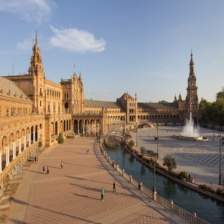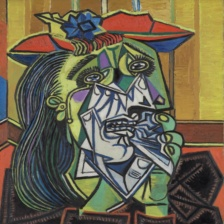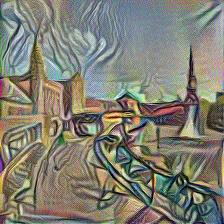

---

## Lab Setup

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from tqdm import tqdm
from torch.nn.parameter import Parameter
from PIL import Image
import io

# IF NOT USING COLAB: comment out the following import statement:
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Select two images: one for content and one for style. The images should have noticeably different content and style from each other to make it clear if the style transfer worked.

In [3]:
# Use this code to upload your own images.
# NOTE: if you are not using Colab, `upload()` will not work. Just make sure the images are on your file system and set `content_path` and `style_path` accordingly.

load_and_normalize = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

def upload():
  print('Upload Content Image')
  file_dict = files.upload()
  content_path = io.BytesIO(file_dict[next(iter(file_dict))])

  print('\nUpload Style Image')
  file_dict = files.upload()
  style_path = io.BytesIO(file_dict[next(iter(file_dict))])
  return content_path, style_path

content_path, style_path = upload()

print("Content Path: {}".format(content_path))
print("Style Path: {}".format(style_path))


Upload Content Image


Saving reghan_and_me2.jpg to reghan_and_me2 (1).jpg

Upload Style Image


Saving Studio Ghibli 1080P, 2K, 4K, 5K HD wallpapers free download.jpg to Studio Ghibli 1080P, 2K, 4K, 5K HD wallpapers free download (1).jpg
Content Path: <_io.BytesIO object at 0x7dec228226b0>
Style Path: <_io.BytesIO object at 0x7dec20066750>


In [4]:
# Load in and normalize the images
content_image_orig = Image.open(content_path)
content_image = load_and_normalize(content_image_orig).unsqueeze(0).to(device)
style_image_orig = Image.open(style_path)
style_image = load_and_normalize(style_image_orig).unsqueeze(0).to(device)


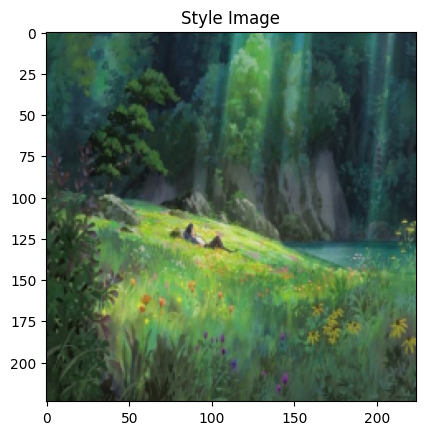

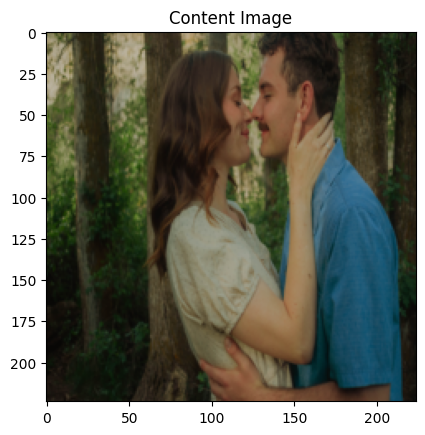

In [5]:
# Display the images
toPIL = transforms.ToPILImage()

def display(tensor, title=None):
    image = tensor.cpu().clone()
    image = image.squeeze(0)
    image = toPIL(image)
    plt.imshow(image)
    if title is not None:
        plt.title(title)
    plt.show()

plt.figure()
display(style_image, title='Style Image')

plt.figure()
display(content_image, title='Content Image')


___

## Part 1


We will use a pretrained VGG-16 network as a feature extractor to get the style and content statistics from the images.

We provide you with the `VGGIntermediate` class to load in the pretrained model and to grab intermediate layers.



* Correctly initialize a VGGIntermediate object to extract style and content
* Gather content statistics from the outputs of intermediate layers for the content image
* Gather style statistics for the style image

In [6]:
import torchvision.models as models

# You should not have to change any of the code in the following classes.

# Normalization layer normalizes the image pixels to mean=0 std=1 according to the statistics of the ImageNet training dataset (which the VGG was pretrained on)
class Normalization(nn.Module):
  def __init__(self):
      super(Normalization, self).__init__()
      self.mean = torch.tensor([0.485, 0.456, 0.406]).view(-1, 1, 1).to(device)
      self.std = torch.tensor([0.229, 0.224, 0.225]).view(-1, 1, 1).to(device)

  def forward(self, img):
      return (img - self.mean) / self.std

# Wrapper for the pretrained VGG-16. Instead of returning the output of the VGG, it returns the `requested` layers.
class VGGIntermediate(nn.Module):
  def __init__(self, requested=[]):
    super(VGGIntermediate, self).__init__()
    self.norm = Normalization().eval()
    self.intermediates = {}
    self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features.eval()
    for i, m in enumerate(self.vgg.children()):
        if isinstance(m, nn.ReLU):   # we want to set the relu layers to NOT do the relu in place.
          m.inplace = False          # the model has a hard time going backwards on the in place functions.

        if i in requested:
          # This stores the output of the requested layer as `intermediates[i]`
          def curry(i):
            def hook(module, input, output):
              self.intermediates[i] = output
            return hook
          m.register_forward_hook(curry(i))

  def forward(self, x):
    self.vgg(self.norm(x))
    return self.intermediates.copy()

We provide you with the list of VGG-16 layer names. Select the names of the layers you'd like to use to extract the content and style ([Gatys et. al. (2016)](https://arxiv.org/pdf/1508.06576.pdf) has suggestions on which layers to use on pages 3 and 12).

Save the layer indexes (not names) into a list for the `requested` parameter of `VGGIntermediate`.

In [7]:
vgg_names = ["conv1_1", "relu1_1", "conv1_2", "relu1_2", "maxpool1", "conv2_1", "relu2_1", "conv2_2", "relu2_2", "maxpool2", "conv3_1", "relu3_1", "conv3_2", "relu3_2", "conv3_3", "relu3_3","maxpool3", "conv4_1", "relu4_1", "conv4_2", "relu4_2", "conv4_3", "relu4_3","maxpool4", "conv5_1", "relu5_1", "conv5_2", "relu5_2", "conv5_3", "relu5_3","maxpool5"]

In [8]:
requested = [0, 5, 10, 17, 19, 24]

Create a `VGGIntermediate` object, providing it with the intermediate layers. You can use a single network to extract both the content and the style, but be sure to keep track of which layers are which.

In [9]:
vgg_intermediate = VGGIntermediate(requested=requested).to(device)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 68.8MB/s]


Use your `VGGIntermediate` network to extract the content from `content_image` and the style from `style_image`. Save these tensors: they will be used throughout training! Be sure to detach these tensors, since these are our labels and we don't want to backpropagate with respect to them.

In [16]:
content_feat = vgg_intermediate(content_image)
content = {layer:feat.detach() for layer, feat in content_feat.items()}

style_feat = vgg_intermediate(style_image)
style = {layer:feat.detach() for layer, feat in style_feat.items()}

---

## Part 2



The loss functions are key to learning the correct behavior in any machine learning problem. For style transfer, we have two losses: content loss and style loss. Our final loss is a combination of both to provide a balance between these competing objectives.

Show that you understand style transfer by describing the key equations of [Gatys et al. 2016](https://arxiv.org/pdf/1508.06576.pdf) in your own words. You may need to read the surrounding sections to understand the equations.

Content Loss:

- Describe equation (1) on p. 10 of (Gatys 2016) in plain English. Include the meaning of all variables and what each dimension represents for each matrix and vector variable.

$\mathcal{L}_{content}(\vec{p}, \vec{x}, l) = \frac{1}{2}\sum_{i,j} (F^l_{ij} - P^l_{ij})^2$

Here $\vec{p}$ and $\vec{x}$ are the original image and a generated image (the image we are trying to optimize). Each image is passed through the network all the way to layer $l$, and the outputs of each are captured as the matrices $P^l$ and $F^l$ respectively. Then the content loss is computed as half the squared Frobenius norm of the two matrices. $F^l$ and $P^l$ are both matrices of dimension $N_l \times M_l$ where $N_l$ is the number of feature maps and $M_l$ is the dimension of the maps.

Style Loss:

- Describe equation (3) on p. 11 of (Gatys 2016) in plain English, including the meaning of all variables and what each dimension represents for each matrix and vector variable (including the output).

$G^l_{ij} = \sum_k F^l_{ik} F^l_{jk}$

Here, $l$ and $F^l$ is as before, and $G^l = F^l (F^l)^T$. $G^l_{ij}$ computes the correlation as an inner product beteween feature maps in layer $l$ corresponding to the generated image $\vec{x}$. $G^l$ will be $N_l \times N_l$, where the $ij$-th element computes the correlation between features $i$ and $j$.


- Describe equation (4) on p. 11 of (Gatys 2016) in plain English, including the meaning of all variables and what each dimension represents for each matrix and vector variable.

$E_l = \frac{1}{4N_l^2M_l^2} \sum_{i,j} (G^l_{ij} - A^l_{ij})^2$

For a given layer $l$, $G^l$ is as described previously, and so are $l$, $M_l$ and $N_l$. Here $A^l$ corresponds to the feature correlation matrix of the original style image in layer $l$, computed in the same manner as $G^l$, just with the original image. Then $E_l$ is computed as the element-wise MSE between $G^l$ and $A^l$, adjusting for the fact that $G^l$ and $A^l$ are symmetric (by dividing by 4).


- Describe equation (5) on p. 11 of (Gatys 2016) in plain English, including the meaning of all variables and subscripts.

$\mathcal{L}_{style}(\vec{a}, \vec{x}) = \sum^L_{l=0} w_lE_l$

The total style loss, depending on the original style image $\vec{a}$ and the generated image $\vec{x}$, is the sum of losses $E^l$ for all layers $l$, each weighted by hyperparameters $\omega_l$ that determine how much each layer should contribute to the loss.

___

## Part 3


Now that you understand the loss functions mathematically, create modules that calculate the content and style loss for a single content or style layer.

Since the targets will be static throughout learning (the content and style images don't change, nor the network), we can store them in the loss module objects, so we don't have to pass them into the forward each time.

In [18]:
# Produces a gram matrix from a 4D tensor input
def gram_matrix(F):
  # batch size, features, height, width
  b, f, h, w = F.size()
  # flatten each image
  F2 = F.view(f, h*w)
  return F2 @ F2.T

# Represents the content loss function for a single content layer
class ContentLoss(nn.Module):
  # Since the targets don't change, store the targets in the init
  def __init__(self, target):
      super().__init__()
      self.target = target

  def forward(self, y_hat): # eq 1 from p 2
      return torch.sum((y_hat - self.target)**2) * 0.5

# Represents the style loss function for a single style layer
class StyleLoss(nn.Module):
  def __init__(self, target):
      super().__init__()
      self.target = target
      self.A = gram_matrix(target)

  def forward(self, y_hat):
      G = gram_matrix(y_hat)
      b, feats, h, w = y_hat.size()
      N = feats
      M = h*w

      return torch.sum((G - self.A)**2) / (2*N*M)**2


# Instantiate a content loss module for each content layer
#  with the content reference image outputs for that layer for comparison
CLoss = {layer:ContentLoss(feat) for layer, feat in content.items()}
# Instantiate a style loss module for each style layer
#  with the style reference image outputs for that layer for comparison
SLoss = {layer:StyleLoss(feat) for layer, feat in style.items()}

Now that you have a list of loss modules, write a loss function that computes the combined style transfer loss. You can weight the overall content and style losses, as well as weighting each layerwise loss value.

Return the combined loss as a tensor for learning. Return the content and style loss values for plotting.

In [35]:
def style_loss(SLoss):
  w_s = torch.ones(len(SLoss)).to(device)
  return sum([w_s[i] * E for i, E in enumerate(SLoss.values())])

___

## Part 4

Create and run a method that minimizes the content and style loss for a copy of the content image

Note that the content loss should be zero if you take out the style loss. Why is that?

**TODO:**

* Use an Adam optimizer (try learning rate of .1, but feel free to experiment)
* Show both the content and the style loss every 50 steps
* Ensure that the outputs don't go out of range (clamp them)
* Display the tensor as an image!
* Experiment with different hyperparameters or network layers until you're satisfied with your final image


First, we need to define our image. While we can create a random image and hope that the optimization works, the best results come from using a clone of the content image. That way, the image starts with the desired content and the content loss only needs to preserve the existing content.

Create a clone of the content image as your initial "generated" image. Calculate and print content and style loss (separately) for your generated image. What do you notice about these losses? Make sure the losses match what you'd expect, given that the generated image is a copy of the content image.

In [64]:
clone = content_image.clone()
clone_feats = vgg_intermediate(clone)
print("Content Loss:", {layer:C(clone_feats[layer]).item() for layer, C in CLoss.items()})
print("Style Loss:", {layer:S(clone_feats[layer]).item() for layer, S in SLoss.items()})

Content Loss: {0: 0.0, 5: 0.0, 10: 0.0, 17: 0.0, 19: 0.0, 24: 0.0}
Style Loss: {0: 0.017618509009480476, 5: 1.4803178310394287, 10: 18.051828384399414, 17: 636.0442504882812, 19: 372.7411804199219, 24: 151.75128173828125}


Prepare your generated image for optimization. You need two things:


1.   Your generated image must require gradients: set requires_grad to true by setting the object parameter `requires_grad` or calling the function `requires_grad_()`.
2.   Create an optimizer with your generated image as the parameter. Torch optimizers expect a list of parameters (or tensors), so you'll need to wrap your generated image in a single-item list for the optimizer.



In [75]:
# Prepare your generated image to learn
clone.requires_grad = True
# Create your optimizer: we suggest starting using an Adam optimizer with lr=.1
optimizer = torch.optim.Adam(params=[clone], lr=0.1)

Now create and run your training loop, storing content and style losses as you train. Remember, you will be optimizing the **generated image** according to the content and style statistics extracted with the network. Print your final image.

For best results, use `torch.clamp_(generated_im.data, 0, 1)` to keep your pixel values in range after each learning step.

Style transfer is very susceptible to overtraining, which introduces a lot of noise to the final image. Print your image often during the training process to find the best-looking image.

Step 0: Content Loss 2598110.75; Style Loss 910.8543701171875.


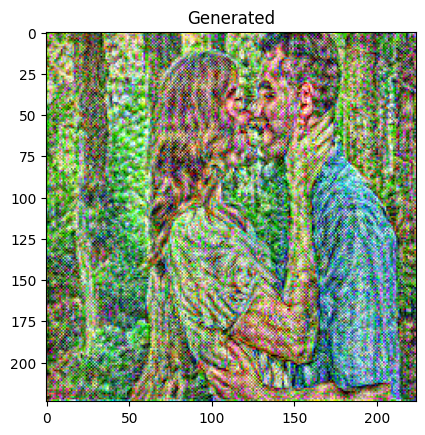

Step 50: Content Loss 1023663.9375; Style Loss 1042.1214599609375.


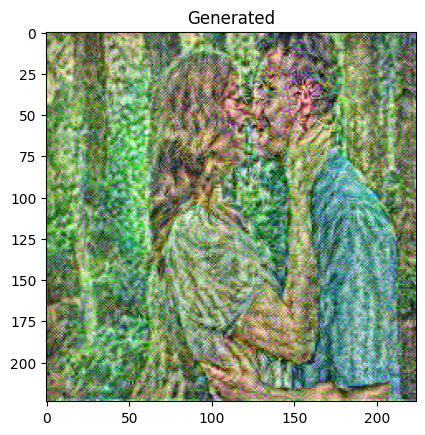

Step 100: Content Loss 1910971.75; Style Loss 655.2799072265625.


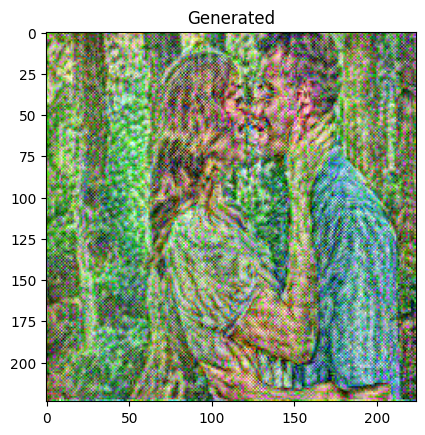

Step 150: Content Loss 1364218.0; Style Loss 852.6677856445312.


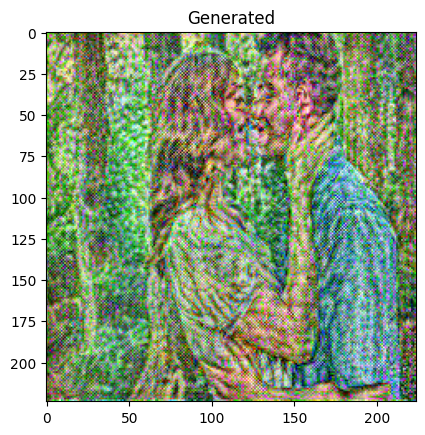

Step 200: Content Loss 1642086.75; Style Loss 1070.558349609375.


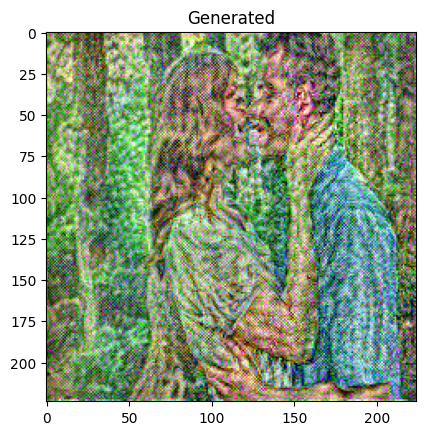

Step 250: Content Loss 1396868.875; Style Loss 924.1024780273438.


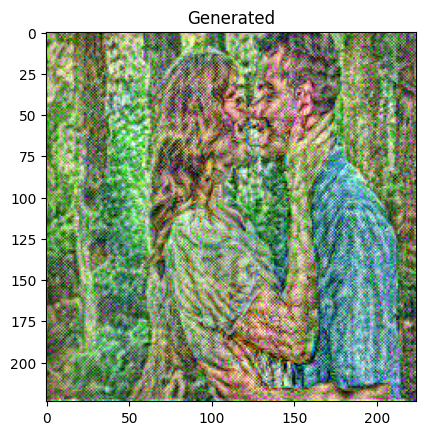

Step 300: Content Loss 1044594.625; Style Loss 1082.2899169921875.


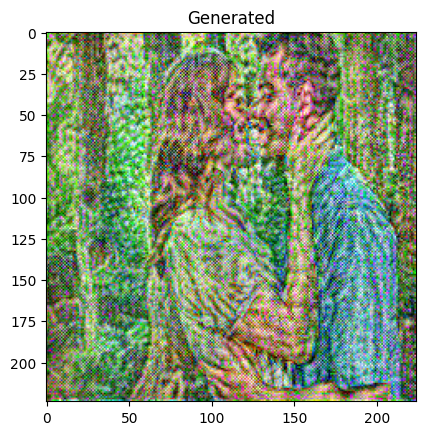

Step 350: Content Loss 1015794.5; Style Loss 928.47509765625.


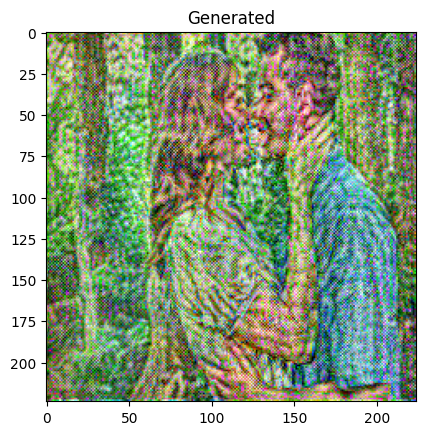

Step 400: Content Loss 1253297.25; Style Loss 940.7365112304688.


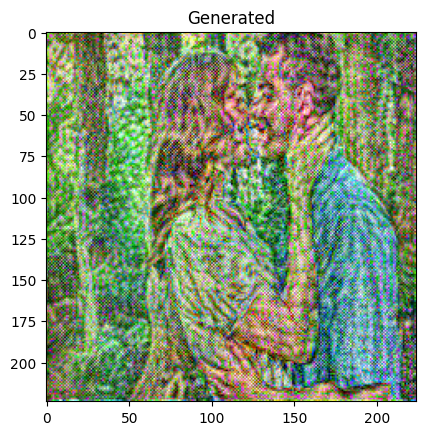

Step 450: Content Loss 1336757.0; Style Loss 903.3419799804688.


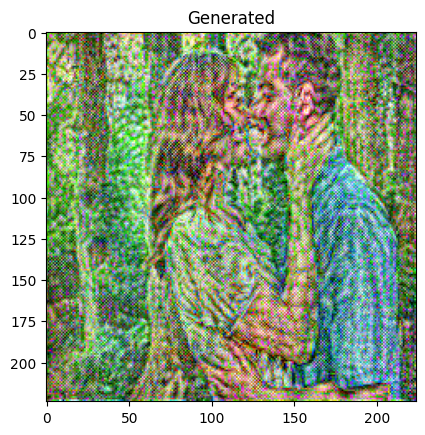

Step 500: Content Loss 1134071.5; Style Loss 1016.9967651367188.


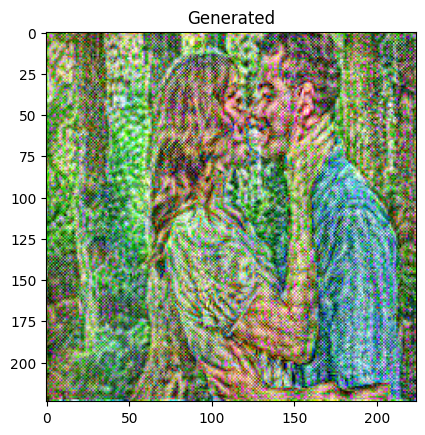

Step 550: Content Loss 1049733.0; Style Loss 1148.572998046875.


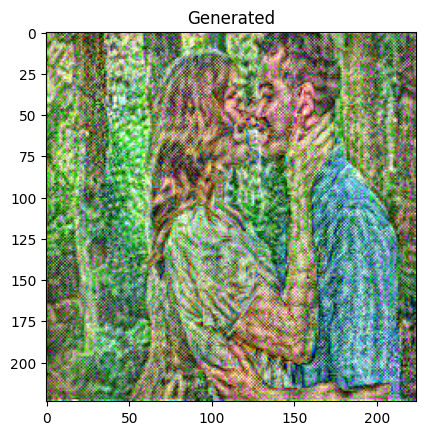

Step 600: Content Loss 1037543.9375; Style Loss 1086.414306640625.


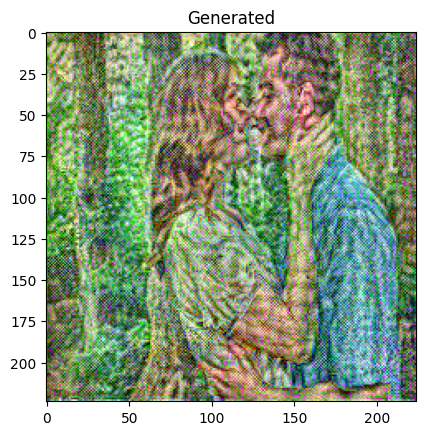

Step 650: Content Loss 1190141.75; Style Loss 1161.070556640625.


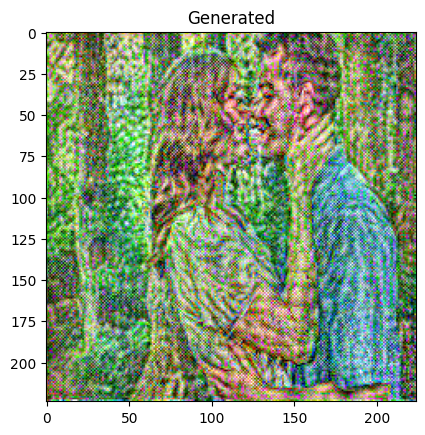

Step 700: Content Loss 1439180.5; Style Loss 1046.8726806640625.


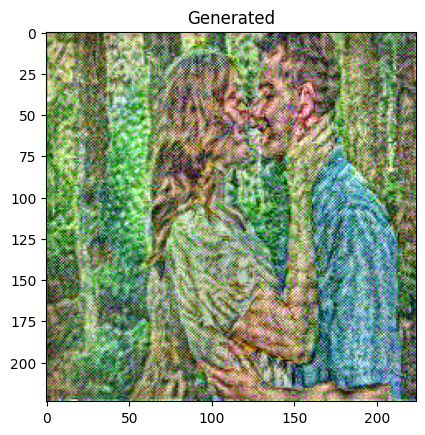

Step 750: Content Loss 801333.375; Style Loss 1038.244140625.


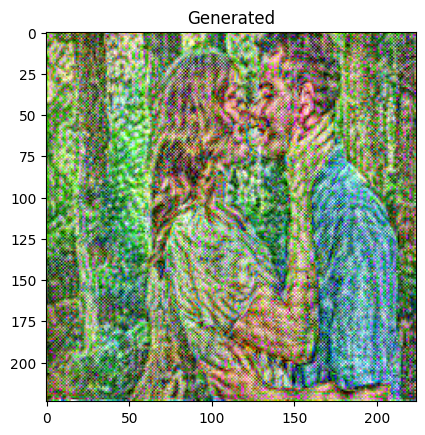

Step 800: Content Loss 807413.25; Style Loss 1168.4730224609375.


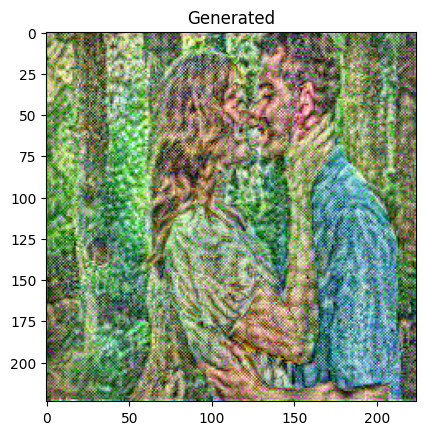

Step 850: Content Loss 1877123.75; Style Loss 875.8909301757812.


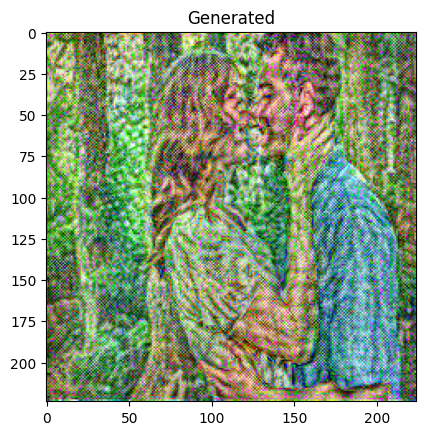

Step 900: Content Loss 2025867.75; Style Loss 904.310546875.


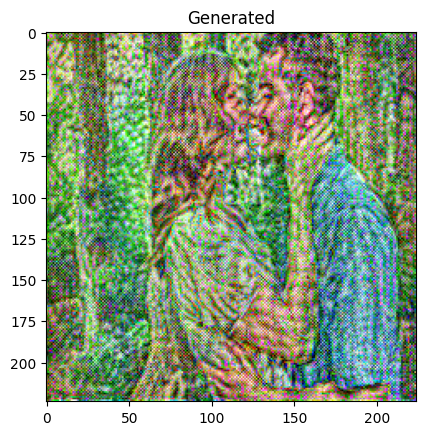

Step 950: Content Loss 948067.5; Style Loss 1278.399169921875.


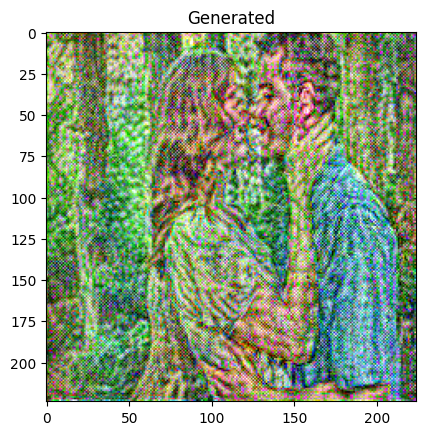

In [76]:
n = 1000
a=1
b=1e3
cl_plt = list()
sl_plt = list()

for i in range(n):
  optimizer.zero_grad()

  clone_feats = vgg_intermediate(clone)
  c_loss = CLoss[19](clone_feats[19])
  s_losses = {layer: S(clone_feats[layer]) for layer, S in SLoss.items()}
  s_loss = style_loss(s_losses)

  total_loss = a * c_loss + b * s_loss
  total_loss.backward()
  optimizer.step()
  clone.data.clamp_(0, 1)

  if i % 50 == 0:
    print(f"Step {i}: Content Loss {c_loss}; Style Loss {s_loss}.")
    display(clone, title="Generated")

  cl_plt.append(c_loss)
  sl_plt.append(s_loss)

Final image:


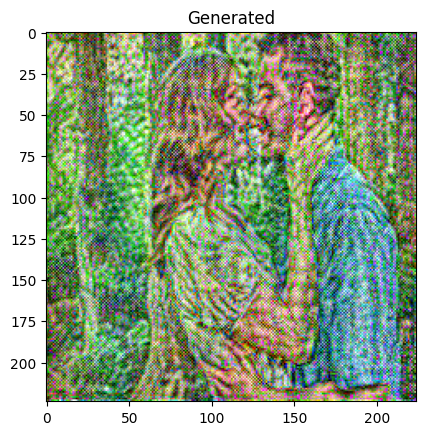

In [77]:
print("Final image:")
display(clone, title="Generated")

Plot your content and style losses. Content loss should start at 0 and increase as style loss decreases. They should both reach an equilibrium.

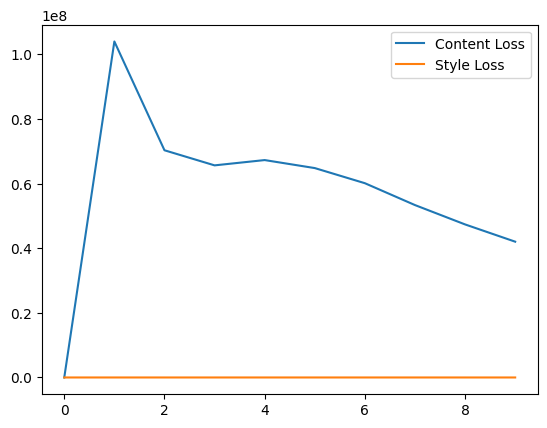

In [37]:
c_loss_plt_cpu = [loss.item() for loss in cl_plt]
s_loss_plt_cpu = [loss.item() for loss in sl_plt]

plt.plot(range(n), c_loss_plt_cpu, label="Content Loss")
plt.plot(range(n), s_loss_plt_cpu, label="Style Loss")
plt.legend()
plt.show()

Now that you have style transfer working, the results may not look very appealing. Different content and style images require different hyperparameters, so you should play around with different network layers, learning rates, and loss weighting to get the best results.